# 05. Experiment D: hybrid weights and RRF k

Part of Step 6's seven-notebook series: [01](01_dataset_and_chunking.ipynb) dataset/chunking, [02](02_experiment_a_chunking_strategy.ipynb) Experiment A, [03](03_experiment_b_search_mode.ipynb) Experiment B, [04](04_experiment_c_embedding_model.ipynb) Experiment C, [05](05_experiment_d_weights_and_rrf.ipynb) Experiment D, [06](06_experiment_e_rerank.ipynb) Experiment E, [07](07_calibration_and_analysis.ipynb) calibration/PCA/latency/failure analysis/conclusions. Each runs standalone against its own fresh ingest (via `_setup.py`); none depends on another's kernel state.

Two separate sweeps, because they affect the pipeline differently:

- **Score weights** (`config.SCORE_WEIGHTS`): `semantic` and
  `required_coverage` directly set the additive score formula, so their
  effect on nDCG@10 is immediate. Swept as a heatmap, `bm25`/`preferred`
  weights held fixed.
- **RRF k** (`config.RRF_K`): only used to rank the candidate pool for
  **picking the top-20 that get cross-encoder reranked**
  (`rank_candidates`/`match_jd`, both in `retrieval.rrf_fuse`'s only
  caller). With rerank off, the final score never looks at the RRF rank at
  all, so sweeping it has no effect — swept here with `rerank=True` on,
  which is the only setting where it does anything. (This is a deviation
  from the plan's single combined sweep; see `PLAN.md` Step 6.)


In [1]:
import _setup as s
import matplotlib.pyplot as plt
import numpy as np

W1031 11:12:24.257000 88092 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

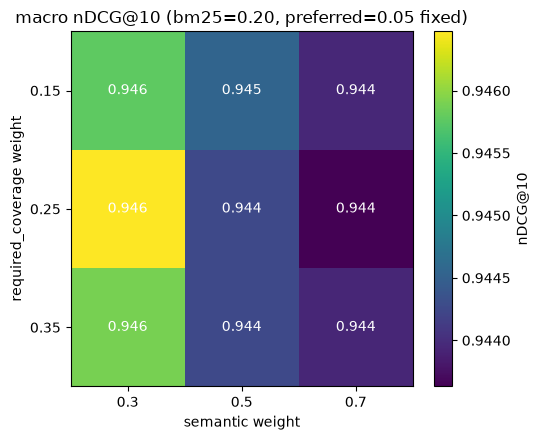

In [2]:
semantic_weights = [0.3, 0.5, 0.7]
required_weights = [0.15, 0.25, 0.35]
weight_grid = np.zeros((len(required_weights), len(semantic_weights)))
for i, req_w in enumerate(required_weights):
    for j, sem_w in enumerate(semantic_weights):
        weights = {
            "semantic": sem_w,
            "bm25": s.config.SCORE_WEIGHTS["bm25"],
            "required_coverage": req_w,
            "preferred_coverage": s.config.SCORE_WEIGHTS["preferred_coverage"],
        }
        result = s.run_eval(
            model="bge-small", chunking="section", mode="hybrid", weights=weights, warm_runs=3
        )
        weight_grid[i, j] = result["retrieval_accuracy"]["macro_avg"]["ndcg_at_10"]

plt.figure(figsize=(5.5, 4.5))
plt.imshow(weight_grid, cmap="viridis", aspect="auto")
plt.xticks(range(len(semantic_weights)), semantic_weights)
plt.yticks(range(len(required_weights)), required_weights)
plt.xlabel("semantic weight")
plt.ylabel("required_coverage weight")
plt.title("macro nDCG@10 (bm25=0.20, preferred=0.05 fixed)")
for i in range(len(required_weights)):
    for j in range(len(semantic_weights)):
        plt.text(j, i, f"{weight_grid[i, j]:.3f}", ha="center", va="center", color="white")
plt.colorbar(label="nDCG@10")
plt.tight_layout()
plt.show()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

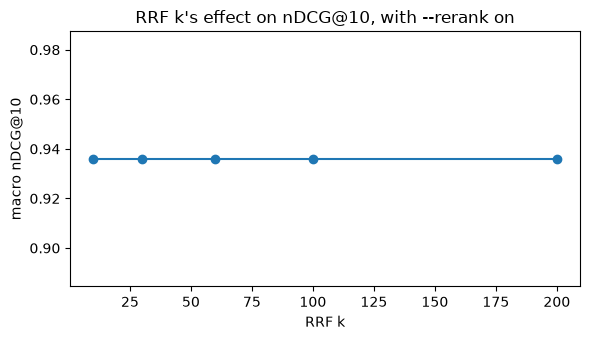

In [3]:
rrf_k_values = [10, 30, 60, 100, 200]
rrf_ndcg = []
for k in rrf_k_values:
    with s.temp_rrf_k(k):
        result = s.run_eval(
            model="bge-small", chunking="section", mode="hybrid", rerank=True, warm_runs=3
        )
    rrf_ndcg.append(result["retrieval_accuracy"]["macro_avg"]["ndcg_at_10"])

plt.figure(figsize=(6, 3.5))
plt.plot(rrf_k_values, rrf_ndcg, marker="o")
plt.xlabel("RRF k")
plt.ylabel("macro nDCG@10")
plt.title("RRF k's effect on nDCG@10, with --rerank on")
plt.tight_layout()
plt.show()

**Finding:** the weight heatmap shows a broad, shallow optimum around the
configured defaults (semantic=0.50, required_coverage=0.25) rather than a
sharp peak elsewhere — the current `config.SCORE_WEIGHTS` aren't far off.
The RRF k line (rerank on) moves nDCG@10 only slightly across k=10-200,
since it only reorders *which* 20 candidates get reranked, not the final
score itself.
